In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
 
import sys
from pathlib import Path


sys.path.append(str(Path.cwd().parent))
import sklearn

In [52]:
bookings=pd.read_csv('/home/rihabehml/GitHubProjects/ML/British-Airways-customers-buying-behavior/data/customer_booking.csv',encoding="cp1252")

In [53]:
bookings.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [54]:
bookings.columns.tolist()

['num_passengers',
 'sales_channel',
 'trip_type',
 'purchase_lead',
 'length_of_stay',
 'flight_hour',
 'flight_day',
 'route',
 'booking_origin',
 'wants_extra_baggage',
 'wants_preferred_seat',
 'wants_in_flight_meals',
 'flight_duration',
 'booking_complete']

In [55]:
bookings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

In [56]:
# missing data
bookings.isna().sum()

num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64

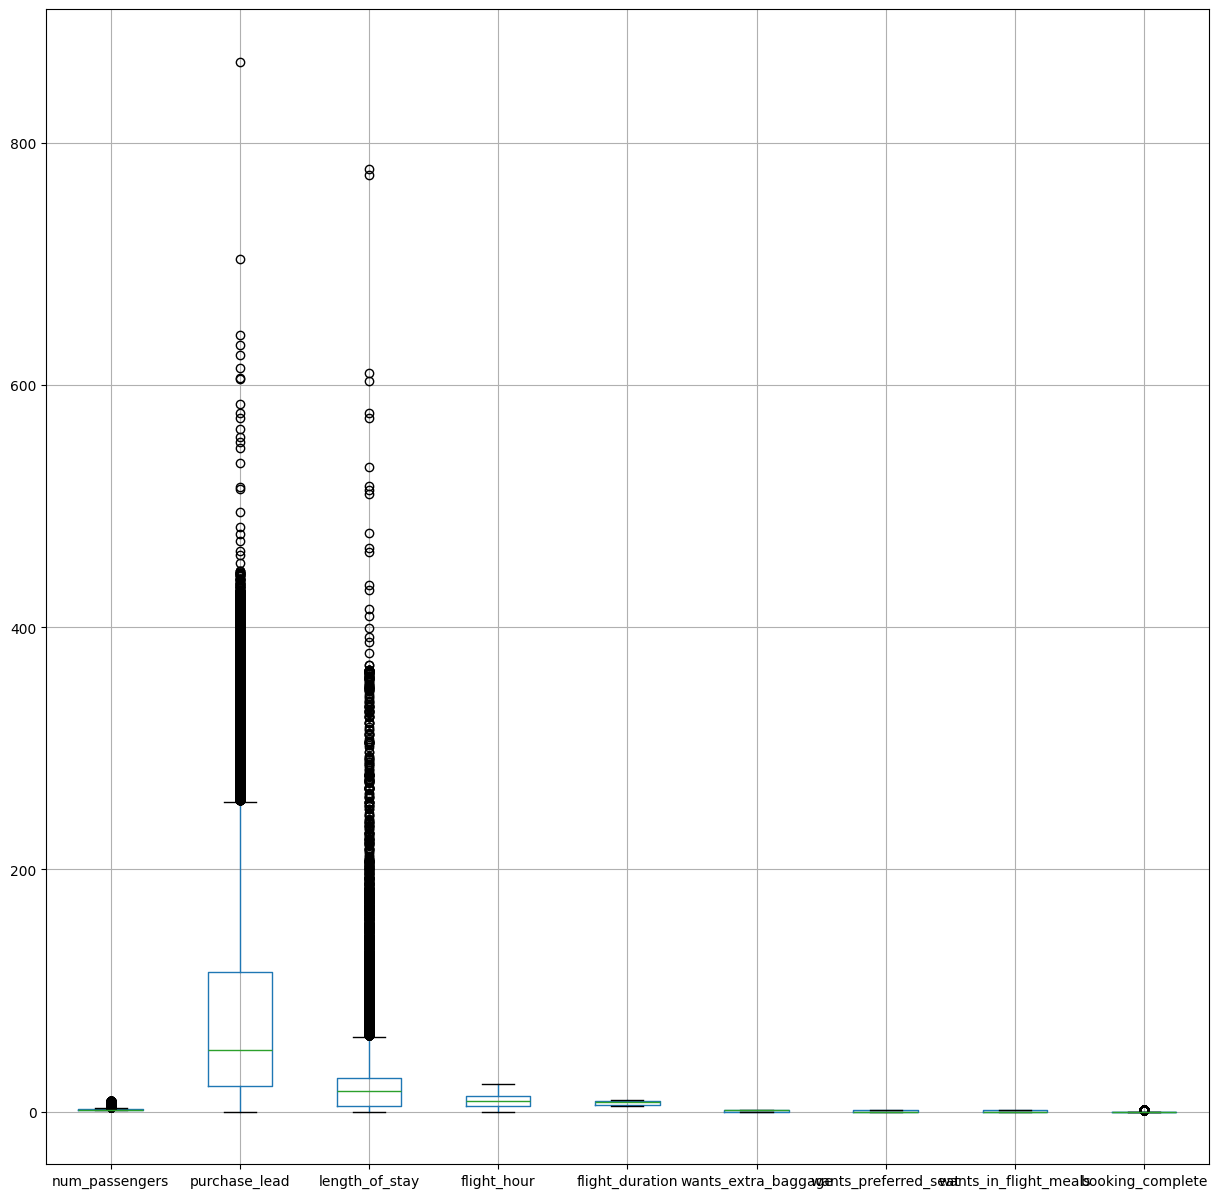

In [57]:
#outliers
bookings.boxplot(column=['num_passengers','purchase_lead','length_of_stay','flight_hour','flight_duration','wants_extra_baggage','wants_preferred_seat','wants_in_flight_meals','booking_complete'],figsize=(15,15))
plt.show()

In [58]:
#negative values
bookings[bookings[['num_passengers','purchase_lead','length_of_stay','flight_hour','flight_duration','wants_extra_baggage','wants_preferred_seat','wants_in_flight_meals','booking_complete']]<0].count()

num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64

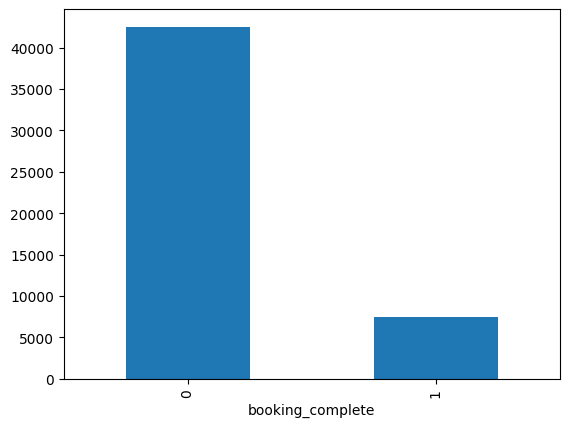

In [59]:
#dataset imbalance
bookings['booking_complete'].value_counts().plot(kind='bar')
plt.show()

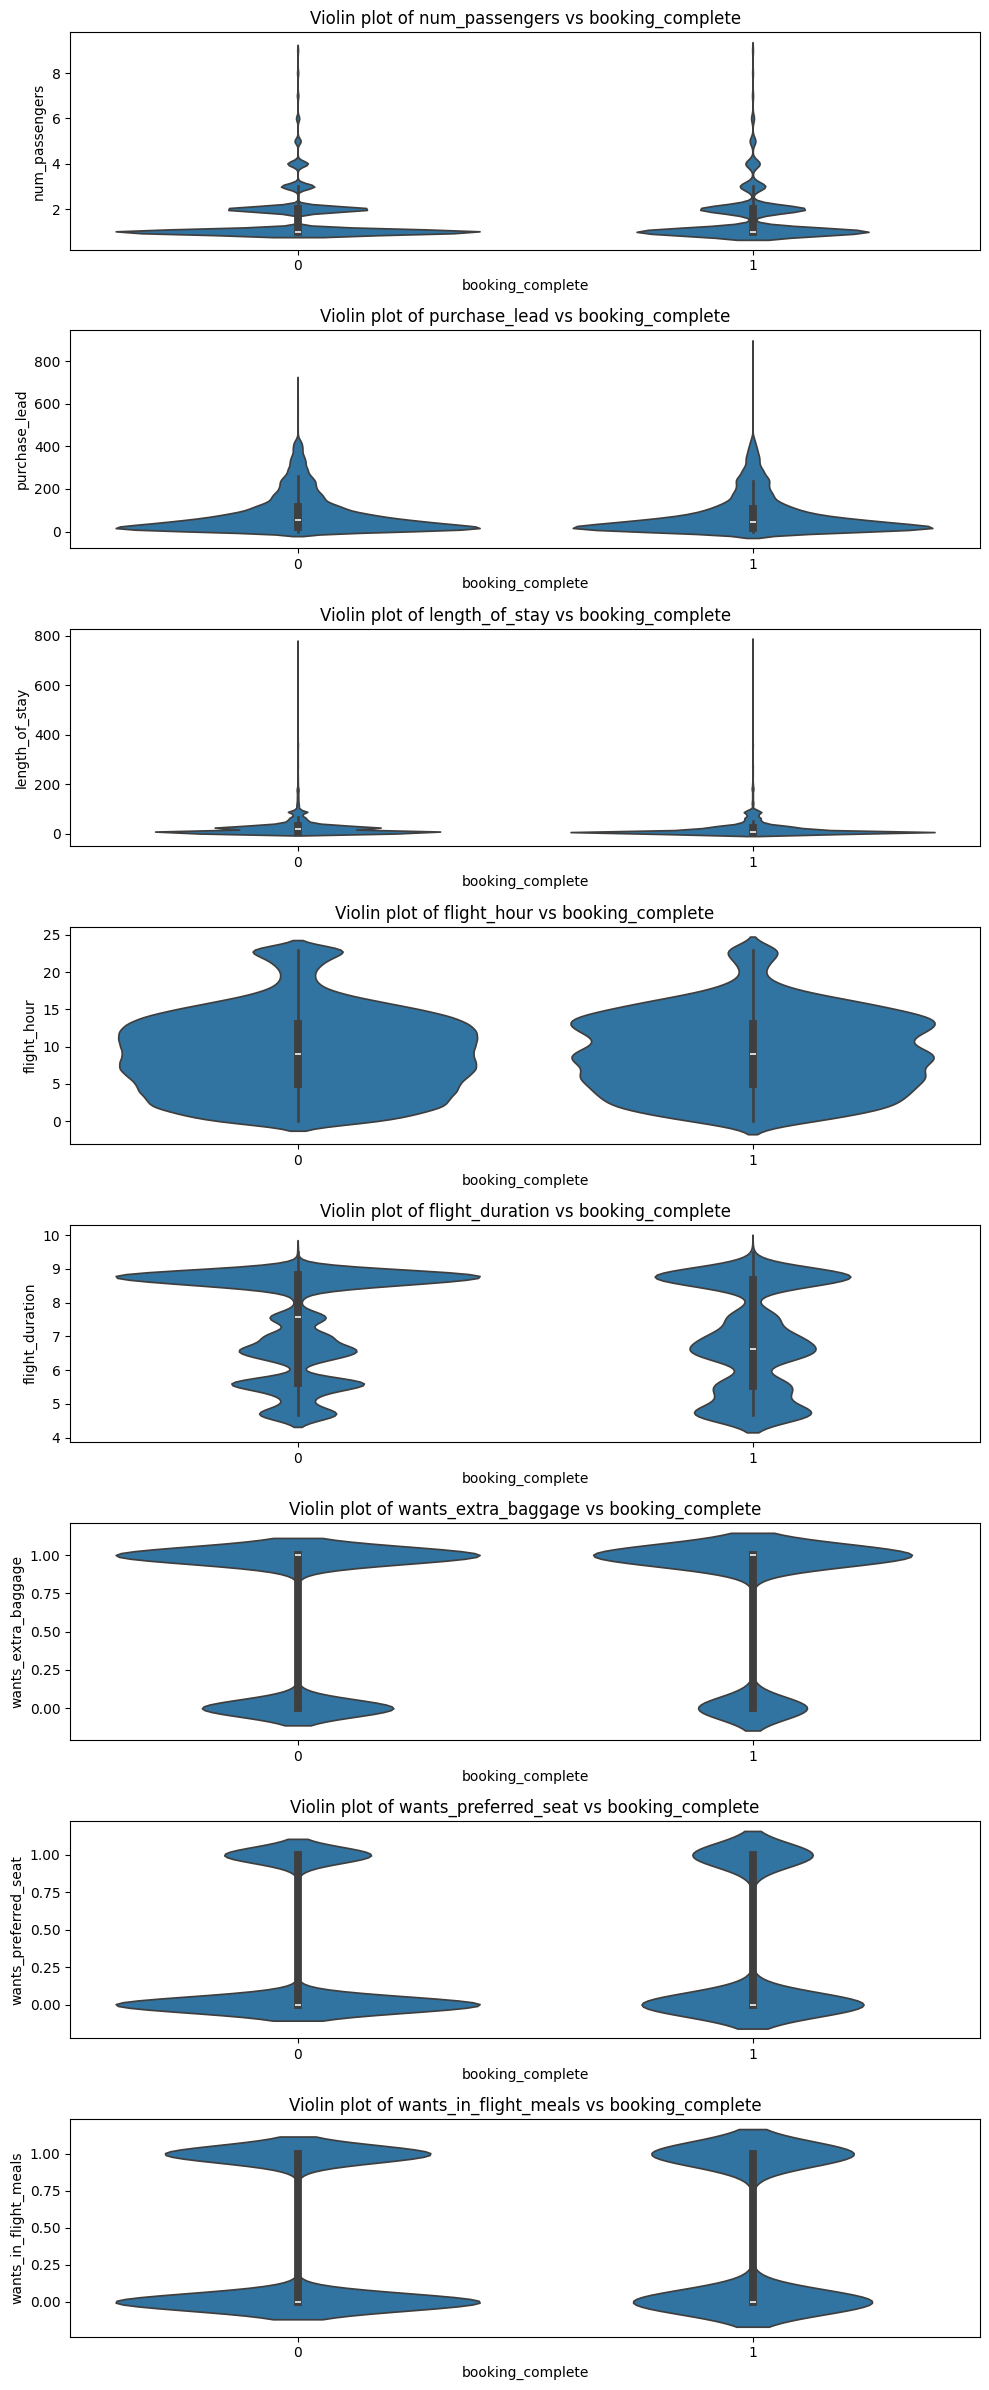

In [60]:
#understand how the distribution of each numerical feature differs between customers who completed a booking (1) and those who did not (0)
from src.Exploring_data_functions import violin_matrix

violin_matrix(bookings,['num_passengers','purchase_lead','length_of_stay','flight_hour','flight_duration','wants_extra_baggage','wants_preferred_seat','wants_in_flight_meals'],'booking_complete')
plt.show()

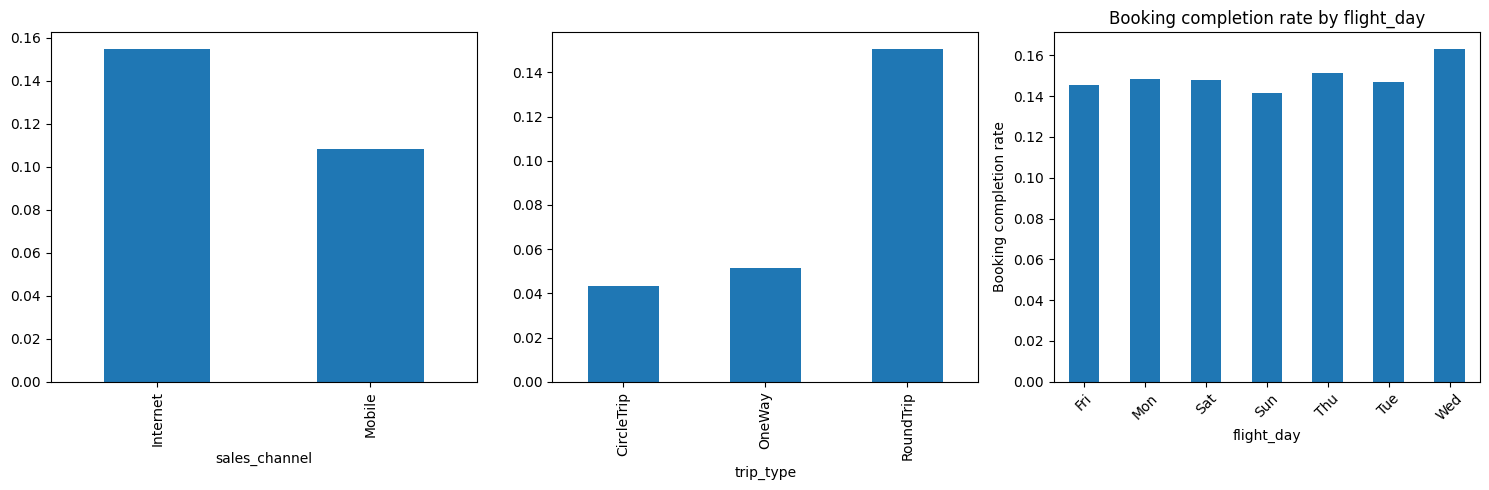

In [69]:
#for non umerical categorical features, we can use bar plots of completion rate
import importlib


importlib.reload(src.Exploring_data_functions)
from src.Exploring_data_functions import barplot_matrix

barplot_matrix(bookings,['sales_channel','trip_type','flight_day'],'booking_complete')
plt.show()

#for 'route' and 'booking_origin': they have too many unique values

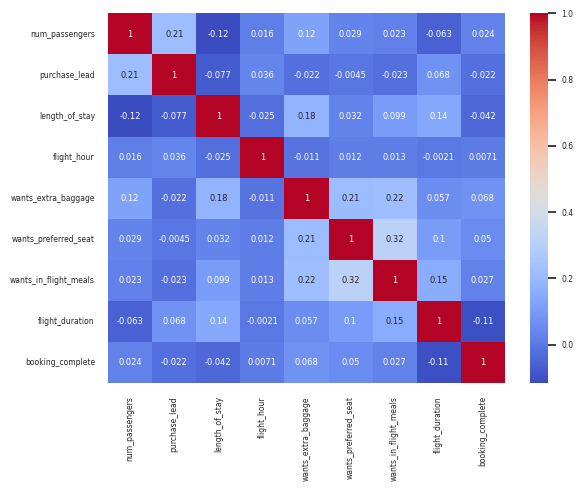

In [84]:
sns.heatmap(bookings.select_dtypes(include="number").corr(),annot=True,cmap="coolwarm")
sns.set(font_scale=1)
plt.show()

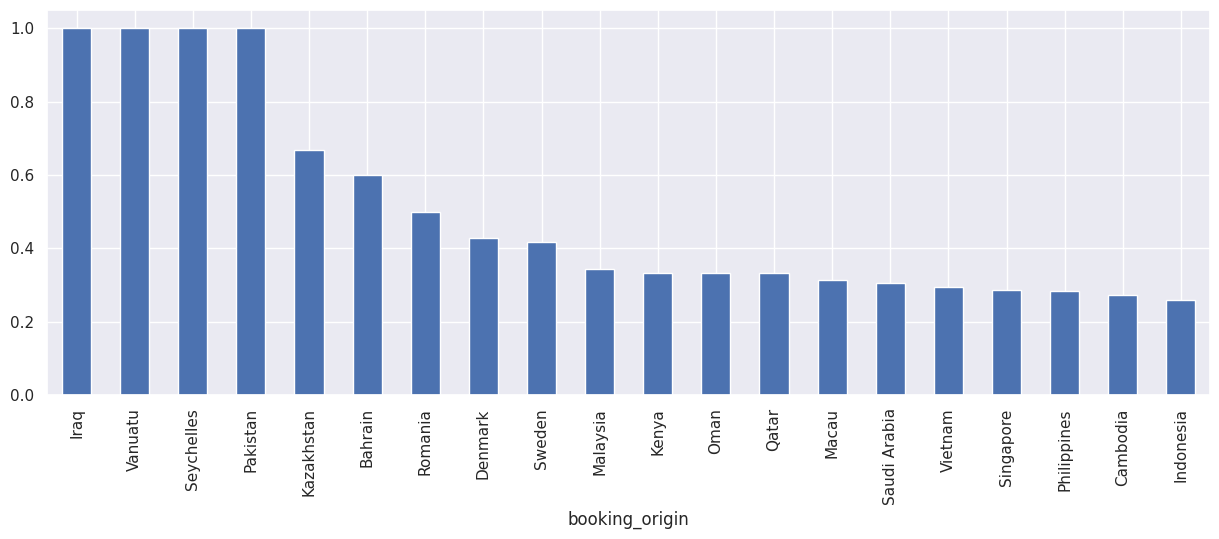

In [99]:
#what countries of origin have the highest completion
completion_rate_booking_origin=bookings.groupby('booking_origin')['booking_complete'].mean().sort_values(ascending=False)
completion_rate_booking_origin.head(20).plot(kind='bar',figsize=(15,5))
plt.show()

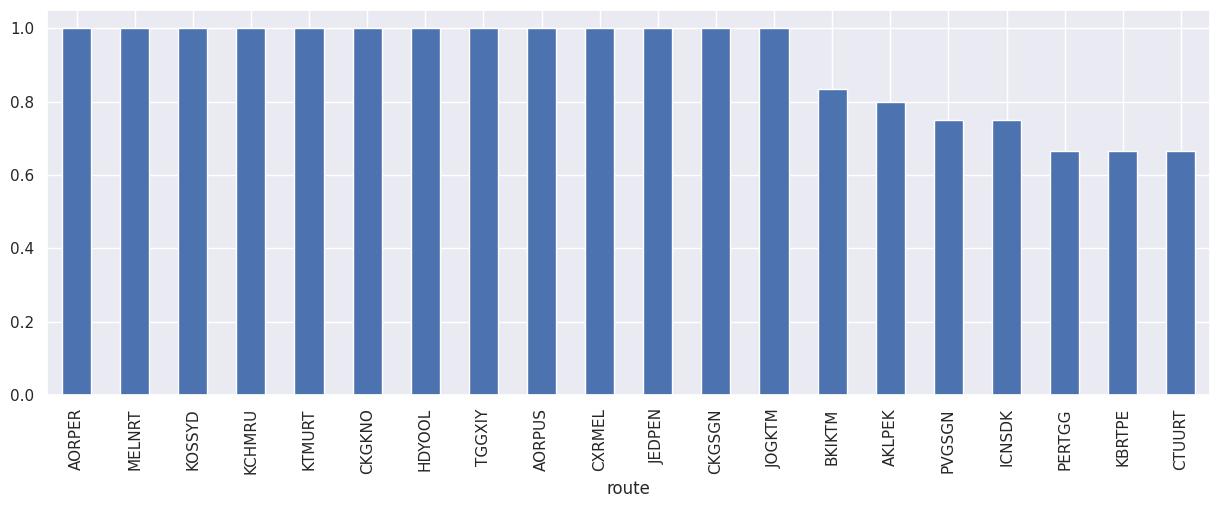

In [ ]:
#what routes have the highest completion rate?
completion_rate_route=bookings.groupby('route')['booking_complete'].mean().sort_values(ascending=False)
completion_rate_route.head(20).plot(kind='bar',figsize=(15,5))
plt.show()

In [134]:
#encoding
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.compose import make_column_transformer
#one_hot encoding for categorical features with low cardinality
categorical_cols = ['sales_channel', 'trip_type', 'flight_day']
oneencoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

oneencoded_array = oneencoder.fit_transform(bookings[categorical_cols])

oneencoded_df = pd.DataFrame(
    oneencoded_array,
    columns=oneencoder.get_feature_names_out(),
    index=bookings.index
)
oneencoded_df.head()
#target encoding
high_categorical_cols = ['route','booking_origin']
target_encoder = TargetEncoder()

targetencoded_array = target_encoder.fit_transform(bookings[high_categorical_cols], bookings['booking_complete'])

targetencoded_df = pd.DataFrame(
    targetencoded_array,
    columns=target_encoder.get_feature_names_out(),
    index=bookings.index
)
targetencoded_df.head()


,route,booking_origin
0,0.0,0.052489
1,0.0,0.049639
2,0.0,0.101913
3,0.0,0.052489
4,0.0,0.095886


In [135]:
encoded_bookings=pd.concat([bookings.drop(columns=categorical_cols+high_categorical_cols), oneencoded_df, targetencoded_df], axis=1)
encoded_bookings.head()

,num_passengers,purchase_lead,length_of_stay,flight_hour,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete,sales_channel_Internet,...,trip_type_RoundTrip,flight_day_Fri,flight_day_Mon,flight_day_Sat,flight_day_Sun,flight_day_Thu,flight_day_Tue,flight_day_Wed,route,booking_origin
0,2,262,19,7,1,0,0,5.52,0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.052489
1,1,112,20,3,0,0,0,5.52,0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.049639
2,2,243,22,17,1,1,0,5.52,0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.101913
3,1,96,31,4,0,0,1,5.52,0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.052489
4,2,68,22,15,1,0,1,5.52,0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.095886


In [136]:
encoded_bookings.to_csv('/home/rihabehml/GitHubProjects/ML/British-Airways-customers-buying-behavior/data/encoded_customer_booking.csv',index=False)